In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# Load the cleaned dataset
df = pd.read_csv('/content/cleaned_student_data.csv')

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display first 5 rows
display(df.head())

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())


Dataset Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



Column Names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [ ]:
# 1. Check column data types
print("=== DATA TYPES ===")
print(df.dtypes)
# 2. Check missing values in each column
print("\n=== MISSING VALUES ===")
print(df.isnull().sum())
# 3. Check total missing values
print("\nTotal missing values:", df.isnull().sum().sum())
# 4. Generate descriptive statistics for numerical columns
print("\n=== DESCRIPTIVE STATISTICS ===")
display(df.describe().round(2))
# 5. Check dataset information
print("\n=== DATASET INFO ===")
df.info()

=== DATA TYPES ===
Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer_Influence                object
Physical_Activity              int64
Learning_Disabilities         object
Parental_Education_Level      object
Distance_from_Home            object
Gender                        object
Exam_Score                     int64
dtype: object

=== MISSING VALUES ===
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Sc

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.00,6607.00,6607.00,6607.00,6607.00,6607.00,6607.00
mean,19.98,79.98,7.03,75.07,1.49,2.97,67.24
std,5.99,11.55,1.47,14.40,1.23,1.03,3.89
min,1.00,60.00,4.00,50.00,0.00,0.00,55.00
25%,16.00,70.00,6.00,63.00,1.00,2.00,65.00
50%,20.00,80.00,7.00,75.00,1.00,3.00,67.00
75%,24.00,90.00,8.00,88.00,2.00,4.00,69.00
max,44.00,100.00,10.00,100.00,8.00,6.00,100.00



=== DATASET INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6607 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence            

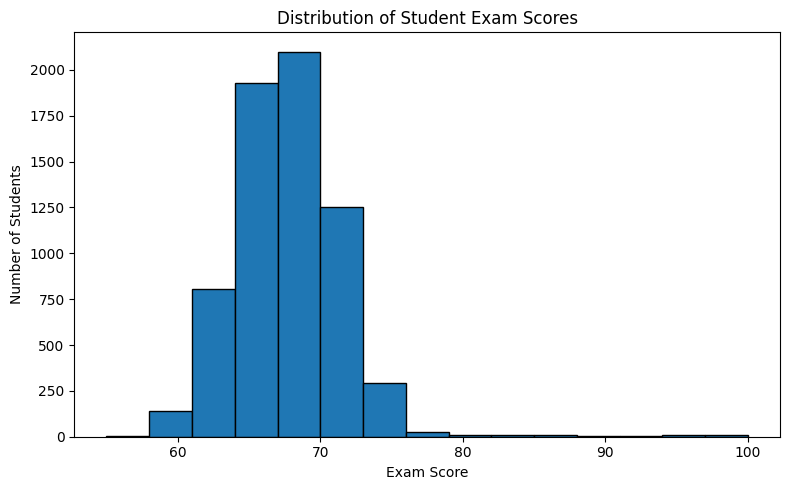

In [ ]:
# Exam Score Distribution
plt.figure(figsize=(8, 5))
plt.hist(df['Exam_Score'], bins=15, edgecolor='black')
plt.title('Distribution of Student Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.show()

,Student_Count,Average_Exam_Score
Attendance_Group,,
60-70%,1734,64.33
71-80%,1689,66.43
81-90%,1594,68.34
91-100%,1590,70.15


Attendance vs Exam Score Correlation: 0.581


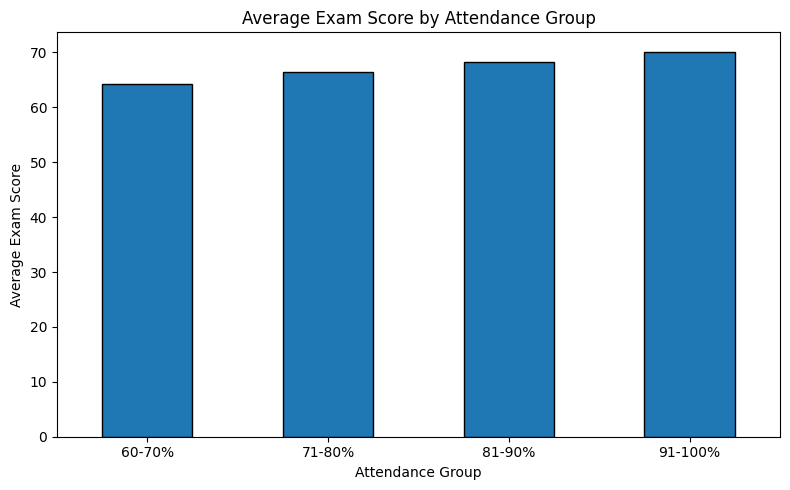

In [ ]:
# Create attendance groups
df['Attendance_Group'] = pd.cut(
    df['Attendance'],
    bins=[59, 70, 80, 90, 100],
    labels=['60-70%', '71-80%', '81-90%', '91-100%'],
    include_lowest=True
)
# Calculate average exam score for each group
attendance_analysis = df.groupby(
    'Attendance_Group', observed=False
).agg(
    Student_Count=('Exam_Score', 'count'),
    Average_Exam_Score=('Exam_Score', 'mean')
).round(2)

display(attendance_analysis)
# Calculate correlation
correlation = df['Attendance'].corr(df['Exam_Score'])

print("Attendance vs Exam Score Correlation:", round(correlation, 3))
# Create bar chart
attendance_analysis['Average_Exam_Score'].plot(
    kind='bar', figsize=(8, 5), edgecolor='black'
)
plt.title('Average Exam Score by Attendance Group')
plt.xlabel('Attendance Group')
plt.ylabel('Average Exam Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Student_Count,Average_Exam_Score
Hours_Studied,,
1,3,71.00
2,6,63.00
3,12,61.33
4,17,61.65
5,21,62.86
6,17,63.47
7,51,64.35
8,58,64.16
9,86,64.16


Study Hours vs Exam Score Correlation: 0.446


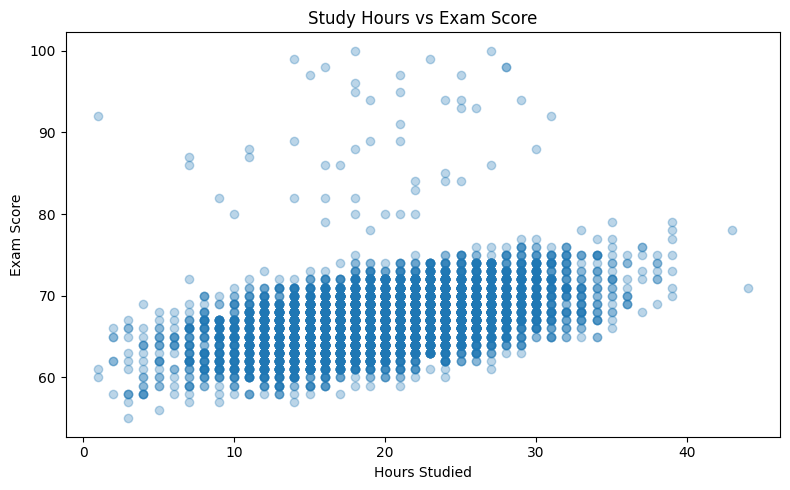

In [5]:
# Group students by hours studied
study_analysis = df.groupby('Hours_Studied').agg(
    Student_Count=('Exam_Score', 'count'),
    Average_Exam_Score=('Exam_Score', 'mean')
).round(2)

# Show the study-hour groups with their average scores
display(study_analysis.head(10))

# Calculate correlation
study_corr = df['Hours_Studied'].corr(df['Exam_Score'])
print("Study Hours vs Exam Score Correlation:", round(study_corr, 3))

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(df['Hours_Studied'], df['Exam_Score'], alpha=0.3)
plt.title('Study Hours vs Exam Score')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.tight_layout()
plt.show()

,Student_Count,Average_Exam_Score
Sleep_Hours,,
4,309,67.63
5,695,67.30
6,1376,67.19
7,1741,67.24
8,1399,67.22
9,775,67.15
10,312,67.14


Sleep Hours vs Exam Score Correlation: -0.017


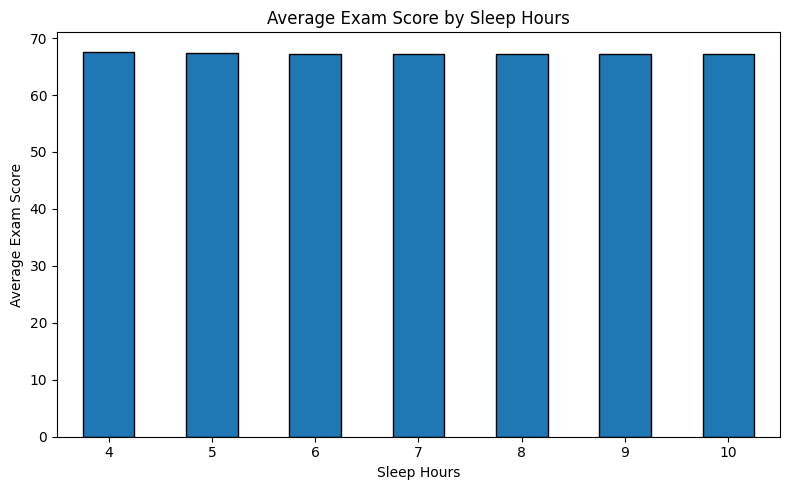

In [6]:
# Average exam score by sleep hours
sleep_analysis = df.groupby('Sleep_Hours').agg(
    Student_Count=('Exam_Score', 'count'),
    Average_Exam_Score=('Exam_Score', 'mean')
).round(2)

display(sleep_analysis)

# Correlation between sleep and exam score
sleep_corr = df['Sleep_Hours'].corr(df['Exam_Score'])
print("Sleep Hours vs Exam Score Correlation:", round(sleep_corr, 3))

# Bar chart
sleep_analysis['Average_Exam_Score'].plot(
    kind='bar', figsize=(8, 5), edgecolor='black'
)

plt.title('Average Exam Score by Sleep Hours')
plt.xlabel('Sleep Hours')
plt.ylabel('Average Exam Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Student_Count,Average_Exam_Score
Motivation_Level,,
High,1319,67.70
Low,1937,66.75
Medium,3351,67.33


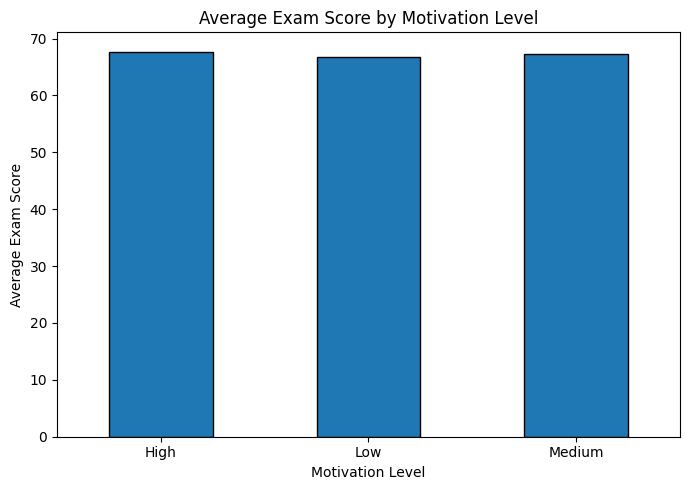

In [7]:
motivation_analysis = df.groupby('Motivation_Level').agg(
    Student_Count=('Exam_Score', 'count'),
    Average_Exam_Score=('Exam_Score', 'mean')
).round(2)

display(motivation_analysis)

motivation_analysis['Average_Exam_Score'].plot(
    kind='bar', figsize=(7, 5), edgecolor='black'
)

plt.title('Average Exam Score by Motivation Level')
plt.xlabel('Motivation Level')
plt.ylabel('Average Exam Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Student_Count,Average_Exam_Score
Parental_Involvement,,
High,1908,68.09
Low,1337,66.36
Medium,3362,67.10


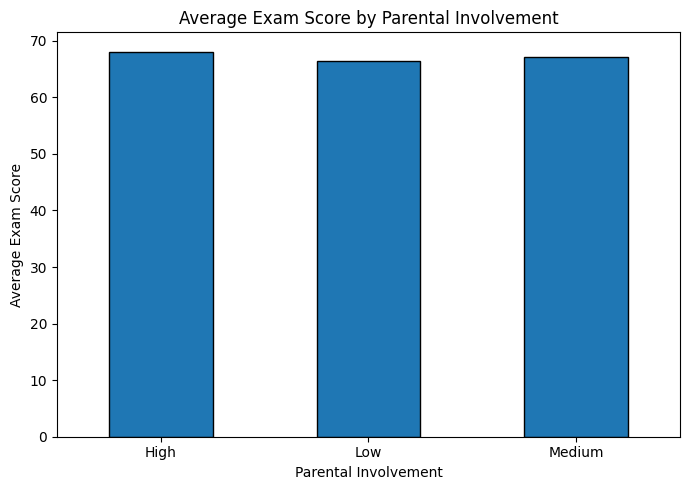

In [8]:
parent_analysis = df.groupby('Parental_Involvement').agg(
    Student_Count=('Exam_Score', 'count'),
    Average_Exam_Score=('Exam_Score', 'mean')
).round(2)

display(parent_analysis)

parent_analysis['Average_Exam_Score'].plot(
    kind='bar', figsize=(7, 5), edgecolor='black'
)

plt.title('Average Exam Score by Parental Involvement')
plt.xlabel('Parental Involvement')
plt.ylabel('Average Exam Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Student_Count,Average_Exam_Score
Internet_Access,,
No,499,66.53
Yes,6108,67.29


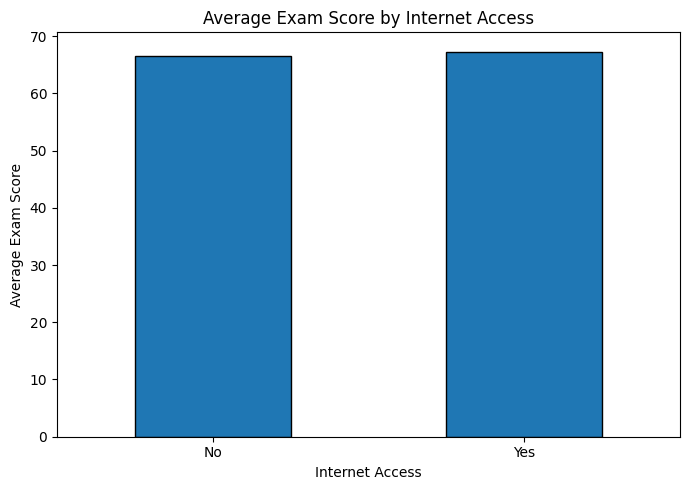

In [9]:
internet_analysis = df.groupby('Internet_Access').agg(
    Student_Count=('Exam_Score', 'count'),
    Average_Exam_Score=('Exam_Score', 'mean')
).round(2)

display(internet_analysis)

internet_analysis['Average_Exam_Score'].plot(
    kind='bar', figsize=(7, 5), edgecolor='black'
)

plt.title('Average Exam Score by Internet Access')
plt.xlabel('Internet Access')
plt.ylabel('Average Exam Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check exam scores outside the expected 0-100 range
print(
    "Exam scores outside 0-100:",
    ((df['Exam_Score'] < 0) | (df['Exam_Score'] > 100)).sum()
)

# Check numeric columns for unexpected values
print("\nNumeric column ranges:")
display(df.describe().loc[['min', 'max']])

# Confirm missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Confirm dataset dimensions
print("Dataset shape:", df.shape)


Duplicate rows: 0
Exam scores outside 0-100: 0

Numeric column ranges:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
min,1.0,60.0,4.0,50.0,0.0,0.0,55.0
max,44.0,100.0,10.0,100.0,8.0,6.0,100.0



Total missing values: 0
Dataset shape: (6607, 20)


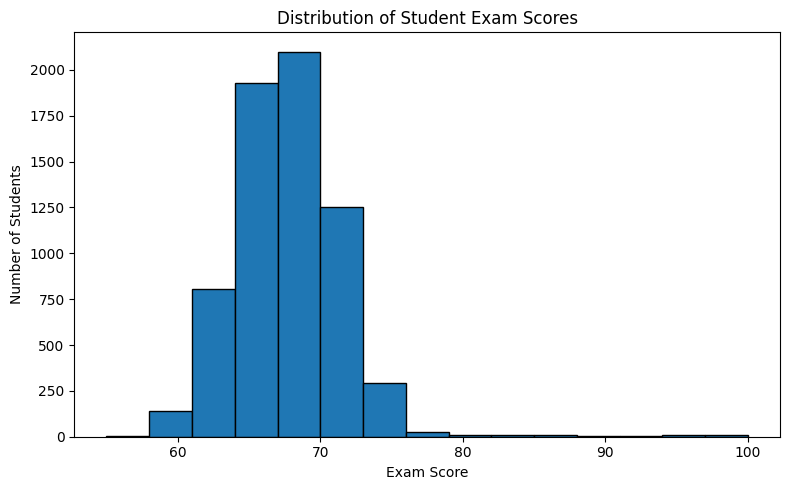

Chart saved successfully!
['exam_score_distribution.png']


In [11]:
import os
# Create a folder for project charts
os.makedirs('/content/eda_charts', exist_ok=True)
# Save the exam score distribution chart
plt.figure(figsize=(8, 5))
plt.hist(df['Exam_Score'], bins=15, edgecolor='black')
plt.title('Distribution of Student Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.savefig('/content/eda_charts/exam_score_distribution.png', dpi=300)
plt.show()
print("Chart saved successfully!")
print(os.listdir('/content/eda_charts'))


In [12]:
import os

chart_path = '/content/eda_charts/exam_score_distribution.png'

print("Chart exists:", os.path.exists(chart_path))
print("File size:", os.path.getsize(chart_path), "bytes")

Chart exists: True
File size: 85966 bytes


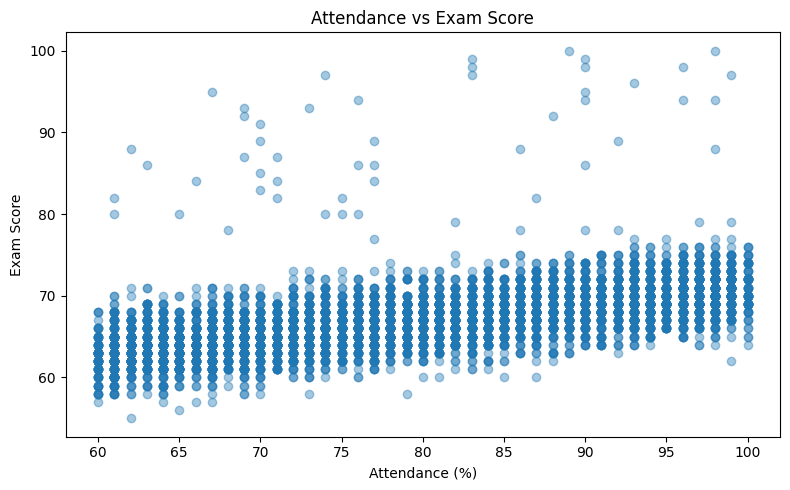

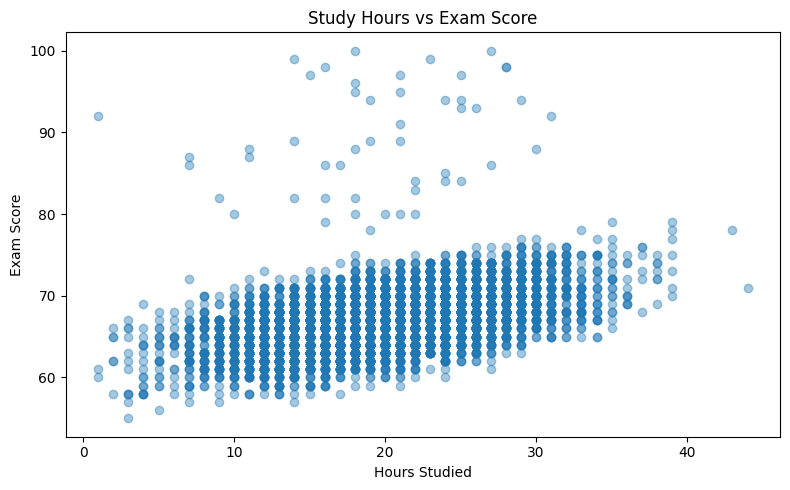

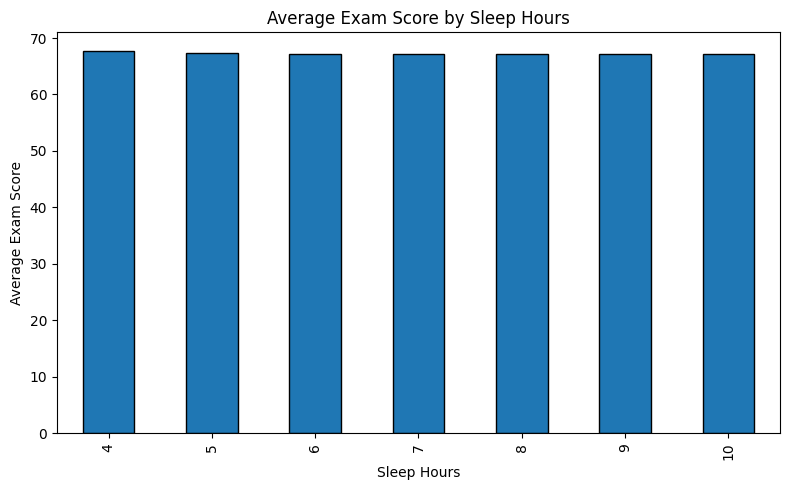

Saved chart files:
['exam_score_distribution.png', 'sleep_hours_vs_exam_score.png', 'attendance_vs_exam_score.png', 'study_hours_vs_exam_score.png']


In [13]:
import os
import matplotlib.pyplot as plt

os.makedirs('/content/eda_charts', exist_ok=True)

# 1. Attendance vs Exam Score
plt.figure(figsize=(8, 5))
plt.scatter(df['Attendance'], df['Exam_Score'], alpha=0.4)
plt.title('Attendance vs Exam Score')
plt.xlabel('Attendance (%)')
plt.ylabel('Exam Score')
plt.tight_layout()
plt.savefig('/content/eda_charts/attendance_vs_exam_score.png', dpi=300)
plt.show()
plt.close()

# 2. Study Hours vs Exam Score
plt.figure(figsize=(8, 5))
plt.scatter(df['Hours_Studied'], df['Exam_Score'], alpha=0.4)
plt.title('Study Hours vs Exam Score')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.tight_layout()
plt.savefig('/content/eda_charts/study_hours_vs_exam_score.png', dpi=300)
plt.show()
plt.close()

# 3. Average Exam Score by Sleep Hours
sleep_analysis = df.groupby('Sleep_Hours')['Exam_Score'].mean()

plt.figure(figsize=(8, 5))
sleep_analysis.plot(kind='bar', edgecolor='black')
plt.title('Average Exam Score by Sleep Hours')
plt.xlabel('Sleep Hours')
plt.ylabel('Average Exam Score')
plt.tight_layout()
plt.savefig('/content/eda_charts/sleep_hours_vs_exam_score.png', dpi=300)
plt.show()
plt.close()

print("Saved chart files:")
print(os.listdir('/content/eda_charts'))

In [14]:
import shutil
shutil.make_archive(
    '/content/eda_charts',
    'zip',
    '/content/eda_charts'
)
print("Chart ZIP created successfully!")

Chart ZIP created successfully!


In [15]:
from google.colab import files
files.download('/content/eda_charts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Student Performance Analysis — Key Findings and Insights

## 1. Project Overview

This project analyzes student academic performance using a dataset containing 6,607 student records and 20 variables. The objective is to explore the relationships between students' study habits, attendance, sleep duration, motivation, parental involvement, internet access, and examination scores.

The analysis uses Python, Pandas, Matplotlib, and exploratory data analysis techniques to identify patterns, evaluate data quality, and communicate actionable insights.

## 2. Dataset Summary

- Total records: 6,607
- Total columns: 20
- Numeric columns: 7
- Categorical columns: 13
- Total missing values: 0
- Duplicate rows: 0
- Minimum exam score: 55
- Maximum exam score: 100
- Average exam score: 67.24
- Median exam score: 67.00

### Interpretation

The dataset contains 6,607 complete records with no detected duplicate rows. The average and median examination scores are close, indicating that the central score distribution is around 67. However, additional distribution analysis is needed to understand the influence of extreme values.

## 3. Data Quality Assessment

The dataset was evaluated for missing values, duplicate records, data types, and numeric ranges.

### Findings

- No missing values were detected across the 20 columns.
- No duplicate rows were detected.
- Numeric and categorical columns were identified.
- Exam scores ranged from 55 to 100, within the expected 0–100 scale.
- Hours studied ranged from 1 to 44.
- Attendance ranged from 60% to 100%.
- Sleep duration ranged from 4 to 10 hours.

### Interpretation

The dataset passed the initial data quality checks. However, valid numeric ranges alone do not guarantee that every observation is realistic. Further validation would be required before using the data for high-stakes decisions.

## 4. Attendance and Examination Performance

The correlation between attendance and exam score was approximately 0.581.

| Attendance Group | Student Count | Average Exam Score |
|---|---:|---:|
| 60–70% | 1,734 | 64.33 |
| 71–80% | 1,689 | 66.43 |
| 81–90% | 1,594 | 68.34 |
| 91–100% | 1,590 | 70.15 |

### Key Insight

The highest-attendance group achieved an average score of 70.15, compared with 64.33 for the lowest-attendance group. This is a difference of 5.82 score points.

### Business Interpretation

Schools could investigate attendance-support initiatives and monitor whether improved attendance is associated with better academic outcomes.

Note: Correlation does not establish that attendance alone causes higher scores.

## 5. Study Hours and Examination Performance

The correlation between hours studied and exam score was approximately 0.446.

### Key Insight

The analysis indicates a moderate positive relationship between study hours and examination scores. Students who study for more hours generally tend to have higher scores, although individual results vary.

### Business Interpretation

Educators could explore structured study schedules, learning support, and study-planning interventions while evaluating their effectiveness over time.

## 6. Sleep Duration and Examination Performance

The correlation between sleep hours and exam score was approximately -0.017.

### Key Insight

The observed linear correlation is very close to zero. Average examination scores also remain relatively similar across the sleep-duration groups.

### Business Interpretation

Sleep duration alone does not explain much of the variation in exam scores in this dataset. Other factors and potential nonlinear relationships may require further investigation.

## 7. Motivation Level and Examination Performance

| Motivation Level | Student Count | Average Exam Score |
|---|---:|---:|
| High | 1,319 | 67.70 |
| Low | 1,937 | 66.75 |
| Medium | 3,351 | 67.33 |

### Key Insight

The high-motivation group has the highest average score at 67.70. However, the difference between the high- and low-motivation groups is only 0.95 points.

### Business Interpretation

Motivation may be worth investigating alongside study habits, learning resources, and previous academic performance. The observed group differences are small and should not be interpreted as proof of causation.

## 8. Parental Involvement and Examination Performance

| Parental Involvement | Student Count | Average Exam Score |
|---|---:|---:|
| High | 1,908 | 68.09 |
| Low | 1,337 | 66.36 |
| Medium | 3,362 | 67.10 |

### Key Insight

The high-parental-involvement group achieved an average score of 68.09, while the low-involvement group achieved 66.36. The difference is 1.73 points.

### Business Interpretation

Schools could explore constructive parent–teacher communication and family engagement initiatives. Further analysis would be needed to assess whether such initiatives influence student outcomes.

## 9. Internet Access and Examination Performance

| Internet Access | Student Count | Average Exam Score |
|---|---:|---:|
| Yes | 6,108 | 67.29 |
| No | 499 | 66.53 |

### Key Insight

Students with internet access scored 0.76 points higher on average than students without access.

### Business Interpretation

Access to digital learning resources may be worth investigating. The small observed difference does not establish that internet access alone improves examination scores.

## 10. Overall Conclusions

The exploratory analysis identified several patterns:

1. Attendance had a positive correlation with examination scores.
2. Study hours had a positive correlation with examination scores.
3. Sleep hours showed almost no linear correlation with examination scores.
4. High-motivation and high-parental-involvement groups had slightly higher average scores.
5. Students with internet access had a slightly higher average score than students without access.
6. Initial data quality checks detected no missing values or duplicate rows.

## 11. Limitations

- The analysis identifies associations, not causal relationships.
- Group averages may hide differences between individual students.
- Correlation measures linear relationships and may not capture nonlinear patterns.
- Potential confounding variables may influence the observed relationships.
- The findings apply to this dataset and should not automatically be generalized to all students.

## 12. Recommended Next Steps

- Examine the relationships between previous scores and current exam performance.
- Investigate access to learning resources and tutoring sessions.
- Explore potential outliers and nonlinear relationships.
- Build an interactive dashboard to communicate findings.
- Publish the notebook, cleaned dataset, visualizations, and project documentation in a GitHub repository.